# Figure S8B — Streaming prediction: throughput vs dataset size

Throughput of `predict_disorder` (black) and `predict_disorder_stream` (red) on the same synthetic datasets. Both run at the same batch size, so any gap between the two lines is the speed cost of streaming.

**How it is made.** One sweep per machine and device from `data/benchmarks/stream/`, written by `benchmarks/stream/benchmark_stream_memory.py` with metapredict 3.1.0 (V3, batch size 32 for both functions, chunk size 20,000, the metapredict 3.1.0 default; every point is measured in a fresh subprocess). For each machine and device the full sweep is preferred over the quick sweep if both exist (the chosen files are printed); one marker shape per machine and device.

**Output:** `figures/figure_S08B.pdf`

In [1]:
import matplotlib.pyplot as plt

from figtools import apply_style, save_panel
from perf_plots import load_results, plot_stream_throughput, stream_sweeps

apply_style()
%matplotlib inline
%config InlineBackend.figure_format = 'retina'

In [2]:
sweeps = stream_sweeps(load_results('stream'))

stream: 54 rows from 5 files; metapredict (version, commit): [('3.1.0+7.g7dcf52c.dirty', '2beafef')]
plotting stream sweep stream_rosalind-2024_V3_cpu_bs32_chunk20000.tsv (M3 Max CPU, 14 measurements)
plotting stream sweep stream_aviation_V3_cpu_bs32_chunk20000.tsv (Xeon Silver 4210R CPU, 14 measurements)
plotting stream sweep stream_aviation_V3_cuda_bs32_chunk20000.tsv (RTX A4000 GPU (CUDA), 14 measurements)


Wrote figures/figure_S08B.pdf


PosixPath('figures/figure_S08B.pdf')

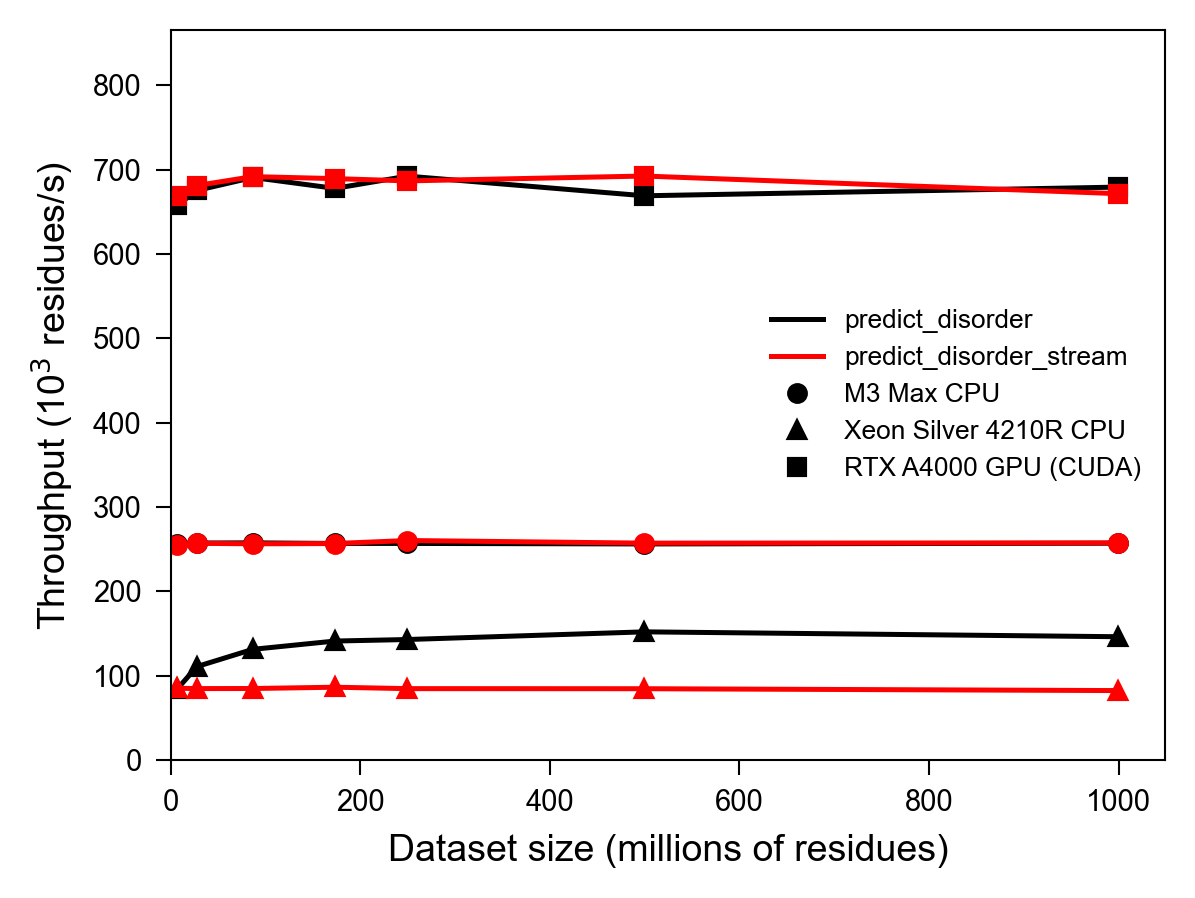

In [3]:
fig, ax = plt.subplots(figsize=(4.1, 3.1), dpi=150)
plot_stream_throughput(ax, sweeps)
plt.tight_layout()
save_panel(fig, 'figure_S08B')